In [27]:
%config InlineBackend.figure_format = "retina"

import seaborn as sns

NEON = [
    "#00F5D4", "#8B5CF6", "#FF4D8D",
    "#FFD166", "#4CC9F0", "#B8F2E6"
]

sns.set_theme(
    style="darkgrid",
    context="notebook",
    palette=NEON,
    font_scale=0.85,
    rc={
        # Keep the same plot dimensions
        "figure.figsize": (15, 5),
        "figure.dpi": 100,
        "savefig.dpi": 300,

        # Dark neon appearance
        "figure.facecolor": "#0B1020",
        "axes.facecolor": "#111827",
        "text.color": "#F8FAFC",
        "axes.labelcolor": "#CBD5E1",
        "axes.titlecolor": "#F8FAFC",
        "xtick.color": "#AAB4C5",
        "ytick.color": "#AAB4C5",

        # Smaller, sharper-looking typography
        "axes.titlesize": 12,
        "axes.titleweight": "semibold",
        "axes.labelsize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,

        # Thin lines and subtle grid
        "lines.linewidth": 1.8,
        "lines.markersize": 4,
        "grid.color": "#334155",
        "grid.alpha": 0.25,
        "grid.linewidth": 0.5,

        # Clean borders and legends
        "axes.spines.top": False,
        "axes.spines.right": False,
        "legend.frameon": False,
    }
)

In [1]:
from datasets import load_dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df.job_posted_date)

c:\Users\abdel\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [9]:
df_spain = df[df['job_country'] == 'Spain'].copy()
df_spain['job_posted_month'] = df_spain['job_posted_date'].dt.month_name()
df_spain['job_posted_month'] = df_spain['job_posted_date'].dt.month_name()
df_spain_pivot = df_spain.pivot_table(index='job_posted_month', columns='job_title_short', aggfunc='size')
df_spain_pivot.reset_index(inplace=True)
df_spain_pivot['job_posted_month_no'] = pd.to_datetime( df_spain_pivot['job_posted_month'], format='%B' ).dt.month
df_spain_pivot.sort_values('job_posted_month_no', inplace=True)
df_spain_pivot.set_index('job_posted_month', inplace=True)
df_spain_pivot.drop(columns='job_posted_month_no', inplace=True)


## NOW we Gonna Try Merge Two Columns -->

In [10]:
df_spain_pivot

job_title_short,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer
job_posted_month,,,,,,,,,,
January,187,65,560,835,597,51,64,218,178,205
February,127,31,399,569,453,48,42,121,111,128
March,74,23,363,558,351,34,35,127,86,92
April,45,24,361,566,380,33,51,99,95,101
May,49,11,395,513,390,29,36,111,65,40
June,77,26,344,440,347,37,39,89,77,79
July,74,22,382,470,427,41,41,96,114,74
August,129,47,541,467,666,54,88,101,159,108
September,127,61,403,517,448,52,37,115,110,142


In [16]:
df_spian_software_pivot = pd.read_csv("https://lukeb.co/software_csv", index_col='job_posted_month')
df_spian_software_pivot

,Front-End Developer,Back-End Developer,Full-Stack Developer,UI/UX Designer
job_posted_month,,,,
January,13619,9827,5108,4348
February,11456,9116,7298,4284
March,11102,8178,5814,4159
April,14037,9209,7232,4220
May,12126,8864,6718,4980
June,12003,8065,5902,4781
July,11914,8061,6839,4344
August,11571,8191,7413,4104
September,14016,8447,6139,4094


In [19]:
df_spain_merged = df_spain_pivot.merge(df_spian_software_pivot, on='job_posted_month')
df_spain_merged

,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer,Front-End Developer,Back-End Developer,Full-Stack Developer,UI/UX Designer
job_posted_month,,,,,,,,,,,,,,
January,187,65,560,835,597,51,64,218,178,205,13619,9827,5108,4348
February,127,31,399,569,453,48,42,121,111,128,11456,9116,7298,4284
March,74,23,363,558,351,34,35,127,86,92,11102,8178,5814,4159
April,45,24,361,566,380,33,51,99,95,101,14037,9209,7232,4220
May,49,11,395,513,390,29,36,111,65,40,12126,8864,6718,4980
June,77,26,344,440,347,37,39,89,77,79,12003,8065,5902,4781
July,74,22,382,470,427,41,41,96,114,74,11914,8061,6839,4344
August,129,47,541,467,666,54,88,101,159,108,11571,8191,7413,4104
September,127,61,403,517,448,52,37,115,110,142,14016,8447,6139,4094


In [25]:
top_5 = df_spain_merged.sum(axis=0).sort_values(ascending=False).head(5).index.tolist()
top_5

['Front-End Developer',
 'Back-End Developer',
 'Full-Stack Developer',
 'UI/UX Designer',
 'Data Engineer']

<Axes: title={'center': 'Top 5 Job Titles in Spain - 2023'}, xlabel='2023', ylabel='Job posting Count'>

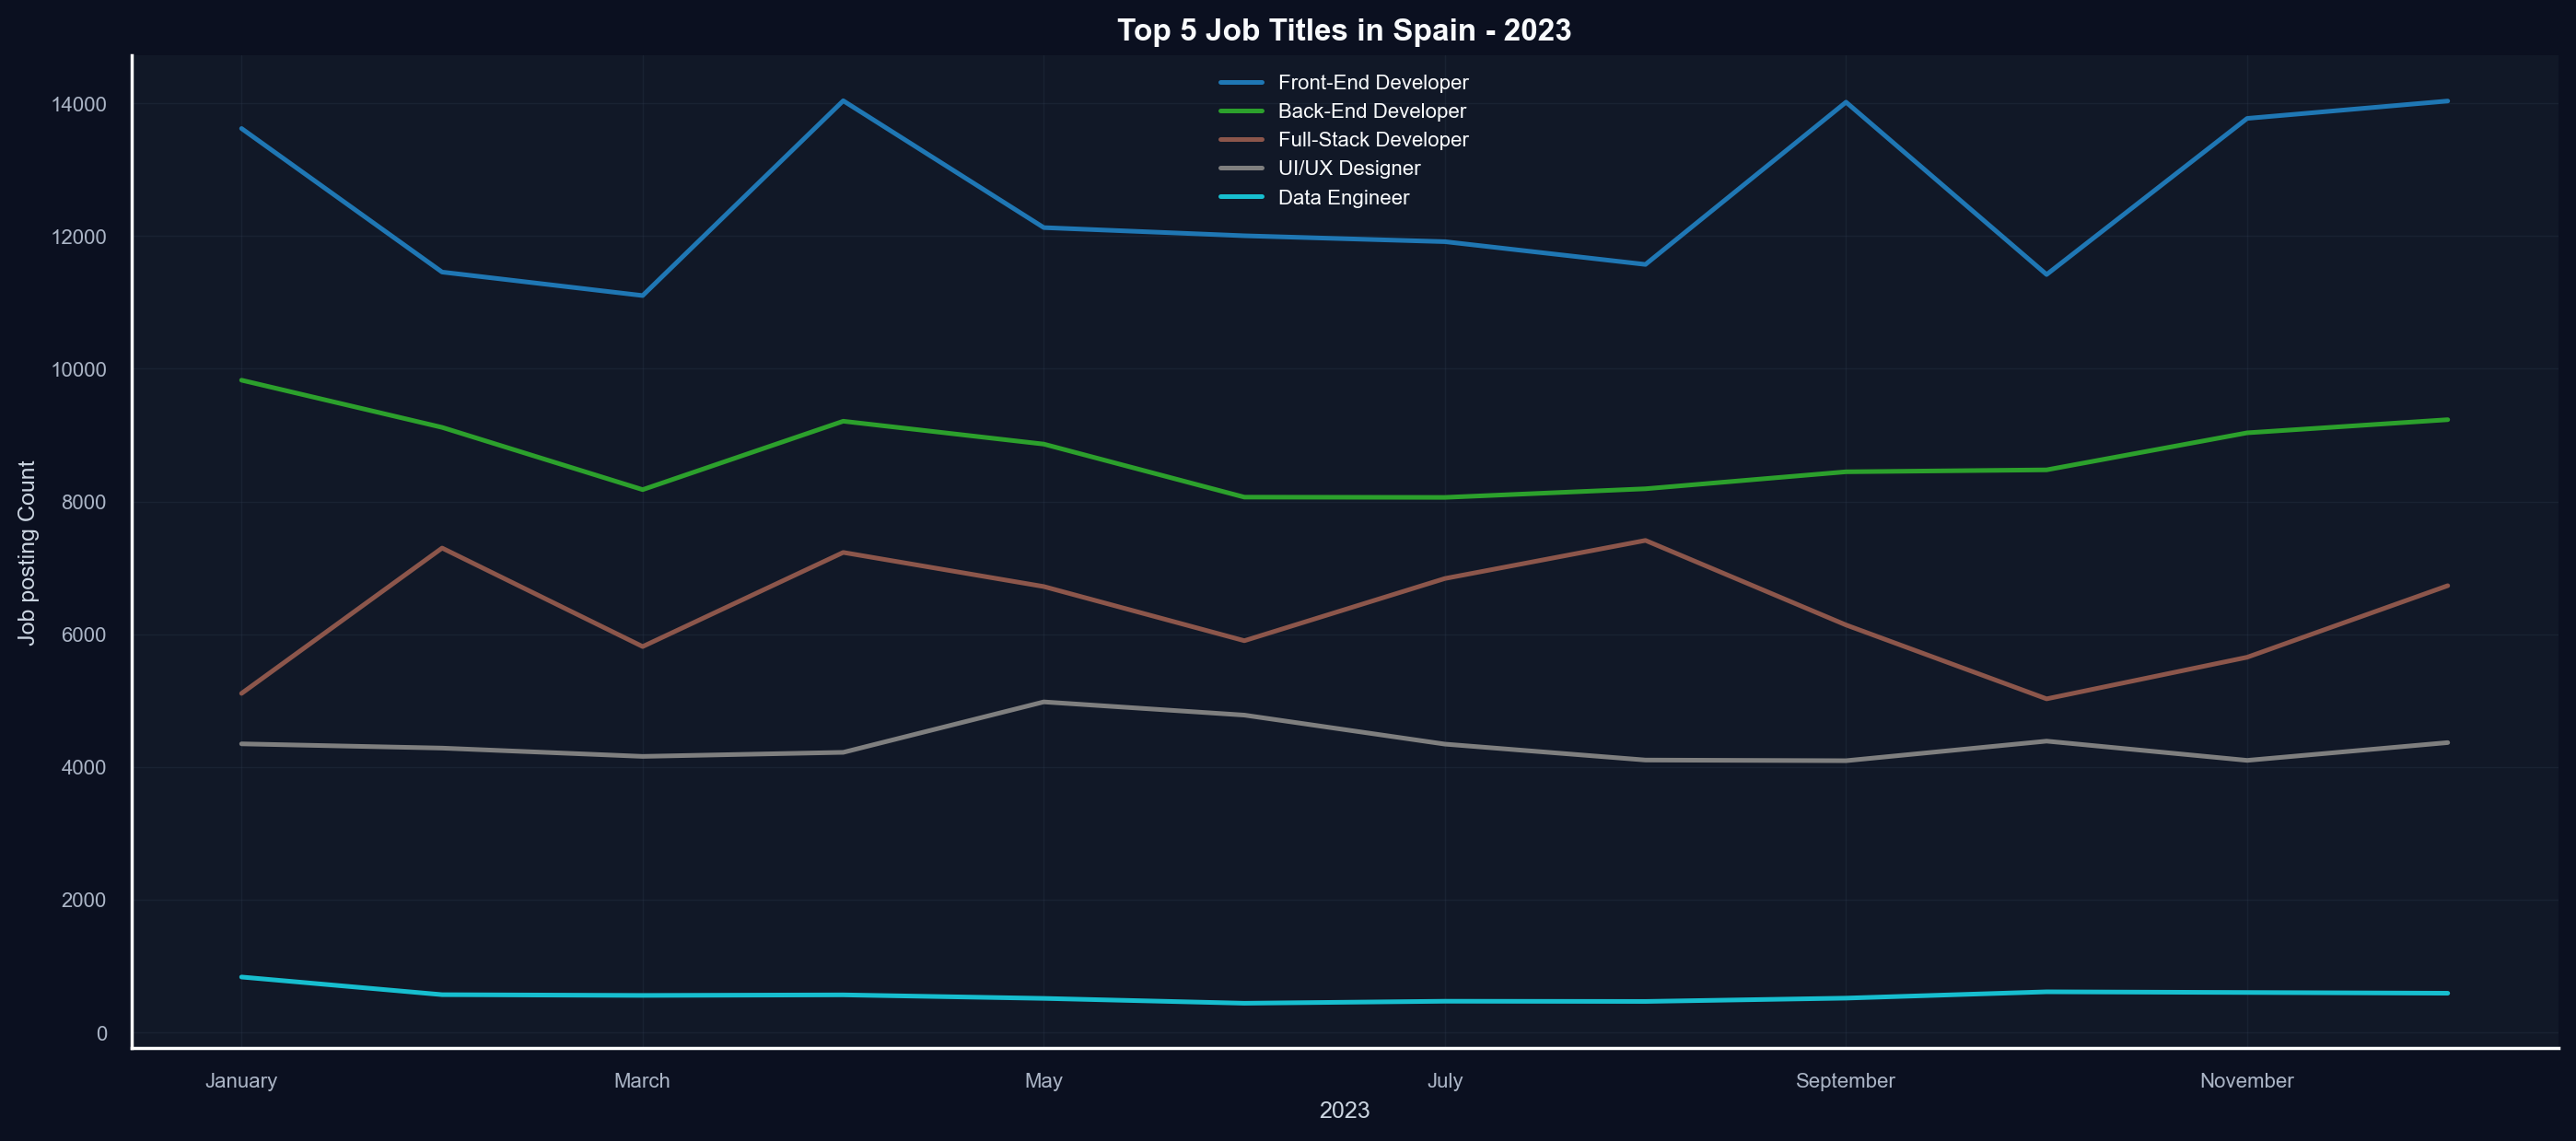

In [42]:
df_spain_merged[top_5].plot(
    kind='line',
    title='Top 5 Job Titles in Spain - 2023',
    xlabel='2023',
    ylabel='Job posting Count',
    figsize=(17, 7),
    grid=True,
    legend=True,
    colormap='tab10',
    )